# 04 - Clustering & Ensemble Models

## Dataset
Hotel Booking Demand dataset  
**Source:** [Kaggle](https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand)

## Objective
Explore booking groups with K-means, hierarchical clustering, and DBSCAN.
Then compare ensemble classification methods, including Random Forest,
AdaBoost, and Gradient Boosting, for cancellation prediction.

C:\Users\aizat\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] Не удается найти указанный файл
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\aizat\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\aizat\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\aizat\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\aizat\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(execu

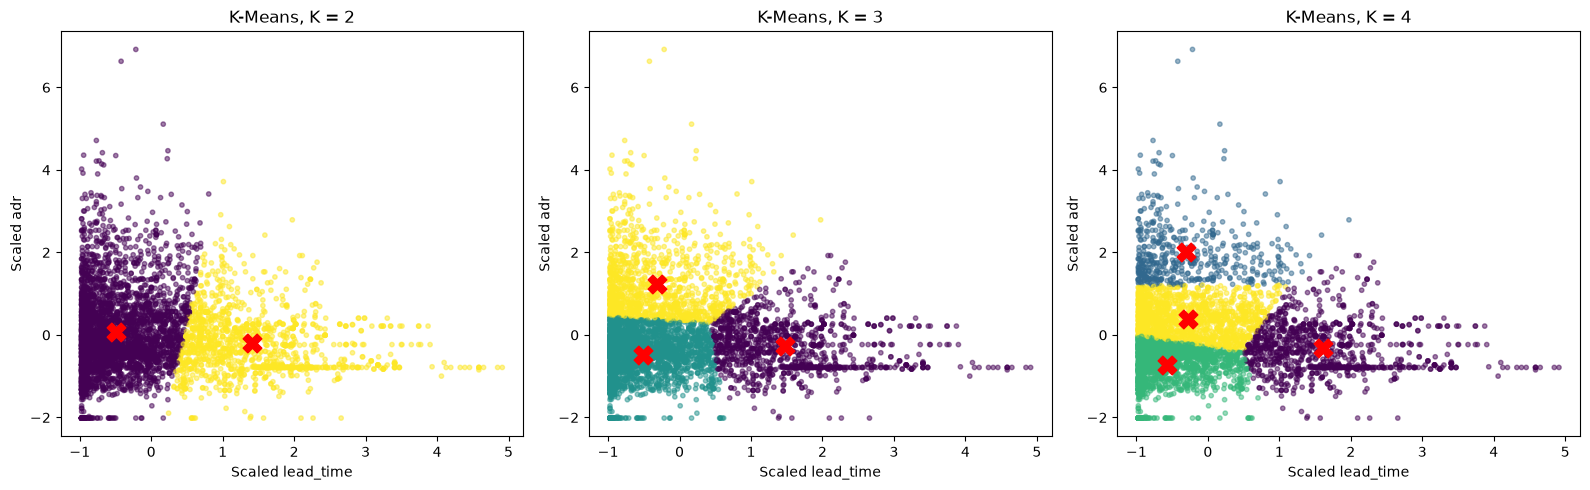

In [3]:
# Part 1 K-Means Clustering

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("hotel_bookings.csv")

features = ["lead_time", "adr"]
cluster_data = df[features].replace([np.inf, -np.inf], np.nan).dropna()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(cluster_data)

plot_size = min(5000, len(X_scaled))
plot_indices = np.random.RandomState(42).choice(
    len(X_scaled), size=plot_size, replace=False
)
X_plot = X_scaled[plot_indices]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, k in zip(axes, [2, 3, 4]):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)

    ax.scatter(
        X_plot[:, 0],
        X_plot[:, 1],
        c=labels[plot_indices],
        cmap="viridis",
        s=10,
        alpha=0.5
    )
    ax.scatter(
        kmeans.cluster_centers_[:, 0],
        kmeans.cluster_centers_[:, 1],
        c="red",
        marker="X",
        s=180
    )
    ax.set_title(f"K-Means, K = {k}")
    ax.set_xlabel("Scaled lead_time")
    ax.set_ylabel("Scaled adr")

plt.tight_layout()
plt.show()

With K = 2, bookings are split into two broad groups, mainly by lead_time. With K = 3, one broad group is divided further based on adr. With K = 4, the data is split into even smaller groups. Increasing K creates more detailed clusters, but may also divide similar bookings into separate groups.

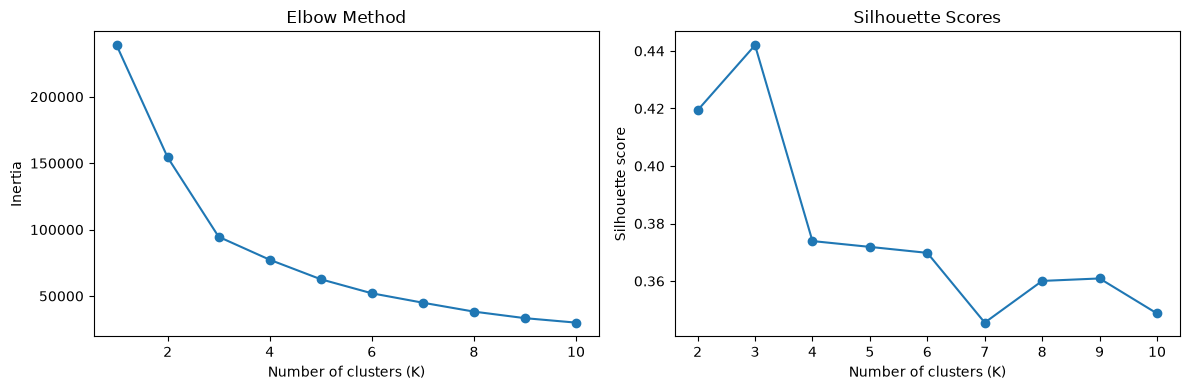

K with the highest silhouette score: 3


In [4]:
# Part 1: Task 2 - Optimal number of clusters

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertias = []
silhouette_scores = []

sample_size = min(3000, len(X_scaled))
sample_indices = np.random.RandomState(42).choice(
    len(X_scaled), size=sample_size, replace=False
)
X_sample = X_scaled[sample_indices]

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertias.append(model.inertia_)

    if k >= 2:
        sample_labels = model.predict(X_sample)
        silhouette_scores.append(
            silhouette_score(X_sample, sample_labels)
        )

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(range(1, 11), inertias, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (K)")
axes[0].set_ylabel("Inertia")

axes[1].plot(range(2, 11), silhouette_scores, marker="o")
axes[1].set_title("Silhouette Scores")
axes[1].set_xlabel("Number of clusters (K)")
axes[1].set_ylabel("Silhouette score")

plt.tight_layout()
plt.show()

best_k = range(2, 11)[np.argmax(silhouette_scores)]
print("K with the highest silhouette score:", best_k)

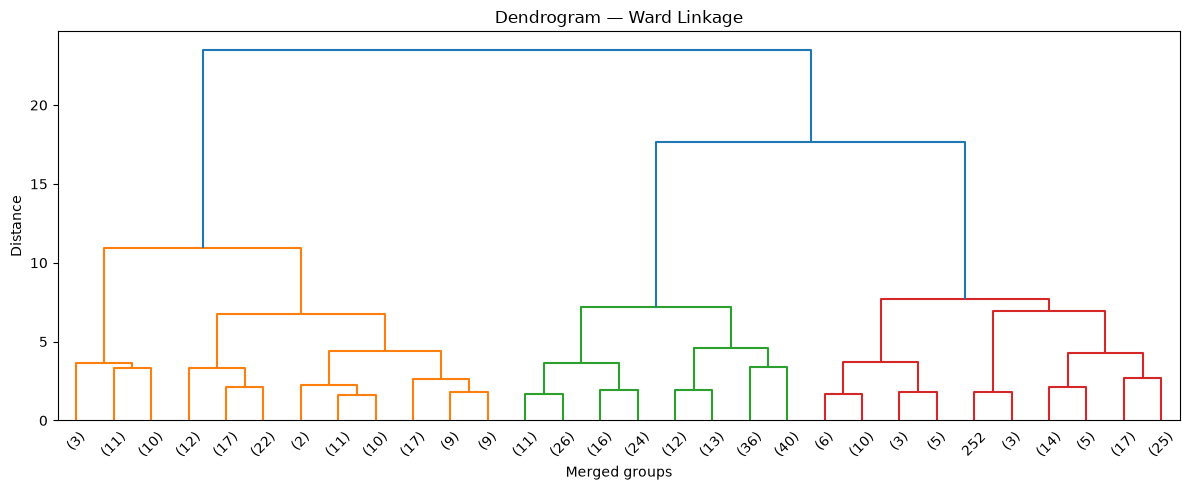

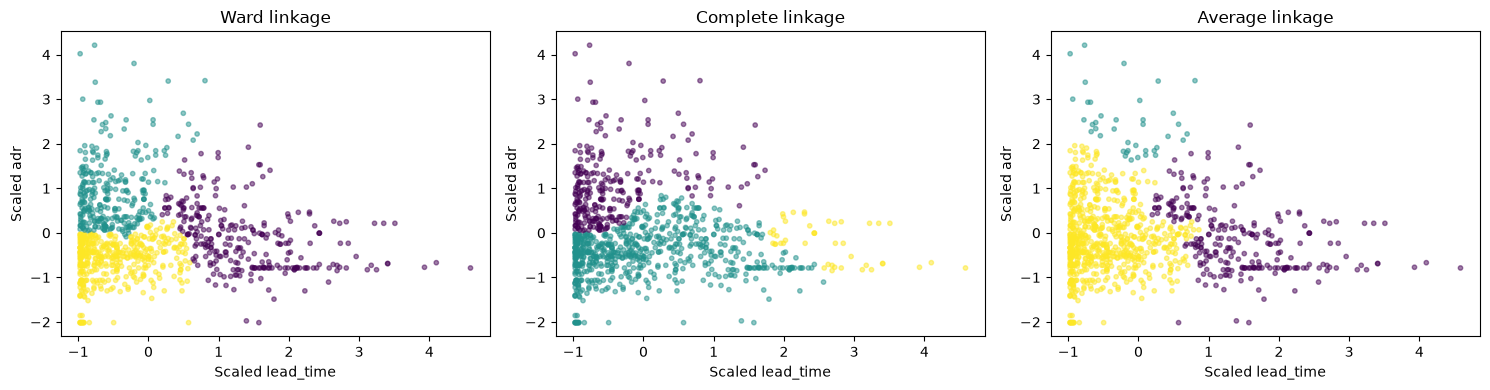

In [5]:
# Part 1: Task 3 - Hierarchical Clustering

from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram

sample_size = min(1000, len(X_scaled))
sample_indices = np.random.RandomState(42).choice(
    len(X_scaled), size=sample_size, replace=False
)
X_hierarchy = X_scaled[sample_indices]

Z = linkage(X_hierarchy[:400], method="ward")

plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode="lastp", p=30)
plt.title("Dendrogram — Ward Linkage")
plt.xlabel("Merged groups")
plt.ylabel("Distance")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, method in zip(axes, ["ward", "complete", "average"]):
    model = AgglomerativeClustering(n_clusters=3, linkage=method)
    labels = model.fit_predict(X_hierarchy)

    ax.scatter(
        X_hierarchy[:, 0],
        X_hierarchy[:, 1],
        c=labels,
        cmap="viridis",
        s=10,
        alpha=0.5
    )
    ax.set_title(f"{method.capitalize()} linkage")
    ax.set_xlabel("Scaled lead_time")
    ax.set_ylabel("Scaled adr")

plt.tight_layout()
plt.show()

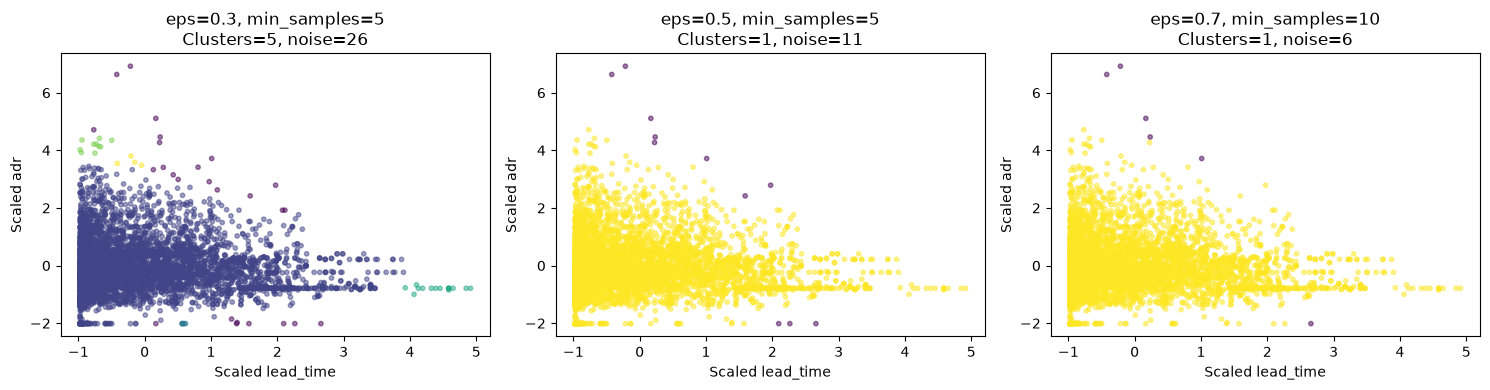

In [6]:
# Part 1: Task 4 — DBSCAN Clustering

from sklearn.cluster import DBSCAN

sample_size = min(5000, len(X_scaled))
sample_indices = np.random.RandomState(42).choice(
    len(X_scaled), size=sample_size, replace=False
)
X_dbscan = X_scaled[sample_indices]

settings = [(0.3, 5), (0.5, 5), (0.7, 10)]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (eps, min_samples) in zip(axes, settings):
    model = DBSCAN(eps=eps, min_samples=min_samples)
    labels = model.fit_predict(X_dbscan)

    cluster_count = len(set(labels)) - (1 if -1 in labels else 0)
    noise_count = np.sum(labels == -1)

    ax.scatter(
        X_dbscan[:, 0],
        X_dbscan[:, 1],
        c=labels,
        cmap="viridis",
        s=10,
        alpha=0.5
    )
    ax.set_title(
        f"eps={eps}, min_samples={min_samples}\n"
        f"Clusters={cluster_count}, noise={noise_count}"
    )
    ax.set_xlabel("Scaled lead_time")
    ax.set_ylabel("Scaled adr")

plt.tight_layout()
plt.show()

In [7]:
# Part 2: Task 5 — Bagging with Random Forest

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

df = pd.read_csv("hotel_bookings.csv")

X = df.select_dtypes(include="number").drop(columns=["is_canceled"])
y = df["is_canceled"]

X = X.replace([np.inf, -np.inf], np.nan)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest (10 trees)": RandomForestClassifier(
        n_estimators=10, random_state=42, n_jobs=-1
    ),
    "Random Forest (50 trees)": RandomForestClassifier(
        n_estimators=50, random_state=42, n_jobs=-1
    ),
    "Random Forest (100 trees)": RandomForestClassifier(
        n_estimators=100, random_state=42, n_jobs=-1
    )
}

results = []

for name, classifier in models.items():
    model = make_pipeline(
        SimpleImputer(strategy="median"),
        classifier
    )
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0)
    })

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(4))

,Accuracy,Precision,Recall,F1-score
Model,,,,
Decision Tree,0.8239,0.7605,0.7655,0.7630
Random Forest (10 trees),0.8559,0.8623,0.7270,0.7889
Random Forest (50 trees),0.8635,0.8644,0.7490,0.8026
Random Forest (100 trees),0.8641,0.8649,0.7504,0.8036


In [8]:
# Part 2: Task 6 — AdaBoost and Gradient Boosting

from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

models = {
    "AdaBoost, 50 estimators": AdaBoostClassifier(
        n_estimators=50, learning_rate=1.0, random_state=42
    ),
    "AdaBoost, 100 estimators": AdaBoostClassifier(
        n_estimators=100, learning_rate=0.5, random_state=42
    ),
    "Gradient Boosting, depth 1": GradientBoostingClassifier(
        n_estimators=100, learning_rate=0.1, max_depth=1, random_state=42
    ),
    "Gradient Boosting, depth 3": GradientBoostingClassifier(
        n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42
    )
}

results = []

for name, classifier in models.items():
    model = make_pipeline(
        SimpleImputer(strategy="median"),
        classifier
    )
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0)
    })

task6_results = pd.DataFrame(results).set_index("Model")
display(task6_results.round(4))

C:\Users\aizat\anaconda3\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(
C:\Users\aizat\anaconda3\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(


,Accuracy,Precision,Recall,F1-score
Model,,,,
"AdaBoost, 50 estimators",0.7840,0.7540,0.6187,0.6797
"AdaBoost, 100 estimators",0.7816,0.7566,0.6050,0.6724
"Gradient Boosting, depth 1",0.7610,0.7276,0.5671,0.6374
"Gradient Boosting, depth 3",0.7900,0.7760,0.6088,0.6823


,Best parameters,Mean CV F1,Test accuracy,Test precision,Test recall,Test F1
Model,,,,,,
Decision Tree,"{'decisiontreeclassifier__max_depth': None, 'd...",0.7565,0.8239,0.7605,0.7655,0.7630
Random Forest,"{'randomforestclassifier__max_depth': None, 'r...",0.8011,0.8641,0.8649,0.7504,0.8036
Gradient Boosting,{'gradientboostingclassifier__learning_rate': ...,0.6822,0.7900,0.7760,0.6088,0.6823


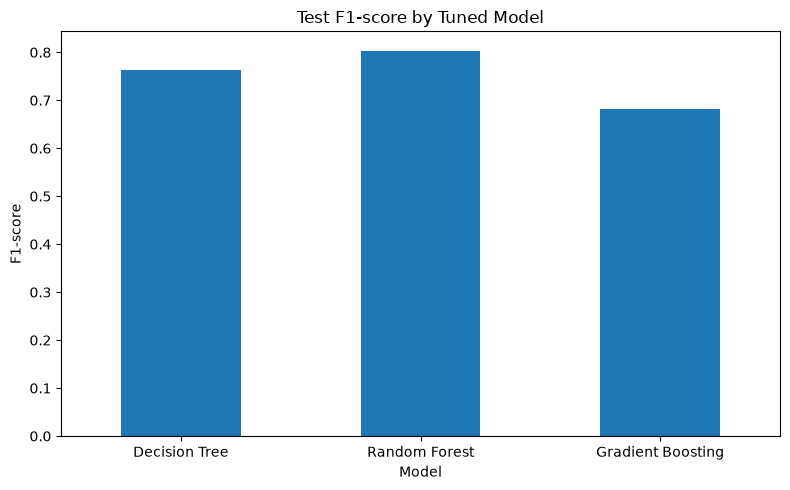

In [9]:
# Part 2: Task 7 — Compare models with GridSearchCV

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

searches = {
    "Decision Tree": (
        make_pipeline(
            SimpleImputer(strategy="median"),
            DecisionTreeClassifier(random_state=42)
        ),
        {
            "decisiontreeclassifier__max_depth": [5, 10, None],
            "decisiontreeclassifier__min_samples_leaf": [1, 10]
        }
    ),
    "Random Forest": (
        make_pipeline(
            SimpleImputer(strategy="median"),
            RandomForestClassifier(random_state=42, n_jobs=1)
        ),
        {
            "randomforestclassifier__n_estimators": [50, 100],
            "randomforestclassifier__max_depth": [10, None],
            "randomforestclassifier__min_samples_leaf": [1, 5]
        }
    ),
    "Gradient Boosting": (
        make_pipeline(
            SimpleImputer(strategy="median"),
            GradientBoostingClassifier(random_state=42)
        ),
        {
            "gradientboostingclassifier__n_estimators": [50, 100],
            "gradientboostingclassifier__learning_rate": [0.05, 0.1],
            "gradientboostingclassifier__max_depth": [1, 3]
        }
    )
}

results = []
best_models = {}

for name, (pipeline, parameters) in searches.items():
    search = GridSearchCV(
        pipeline,
        parameters,
        scoring="f1",
        cv=cv,
        n_jobs=-1
    )
    search.fit(X_train, y_train)

    best_model = search.best_estimator_
    best_models[name] = best_model
    predictions = best_model.predict(X_test)

    results.append({
        "Model": name,
        "Best parameters": search.best_params_,
        "Mean CV F1": search.best_score_,
        "Test accuracy": accuracy_score(y_test, predictions),
        "Test precision": precision_score(y_test, predictions, zero_division=0),
        "Test recall": recall_score(y_test, predictions, zero_division=0),
        "Test F1": f1_score(y_test, predictions, zero_division=0)
    })

task7_results = pd.DataFrame(results).set_index("Model")
display(task7_results.round(4))

task7_results["Test F1"].plot(kind="bar", figsize=(8, 5))
plt.title("Test F1-score by Tuned Model")
plt.ylabel("F1-score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()